In [2]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

#import sys  
sys.path.insert(1,'C:\\Users\\avani\\Desktop\\Spin_Splitting_Ge_ABS')

import Minimal_Model_1D as M

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [8]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
#MEFF_SC = 0.05     # InAs
#MEFF_SM = 0.05     # InAS
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge


NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 20  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 100, 11)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.5 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.5 + OMEGA        ## constant potential over reference level across all widths

K = 12

Ep_li = np.empty((LY.shape[0],K) )
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)


0
10


In [11]:
print(OMEGA[-1]/2, OMEGA[-1]*3/2)

0.6631720133634798 1.9895160400904393


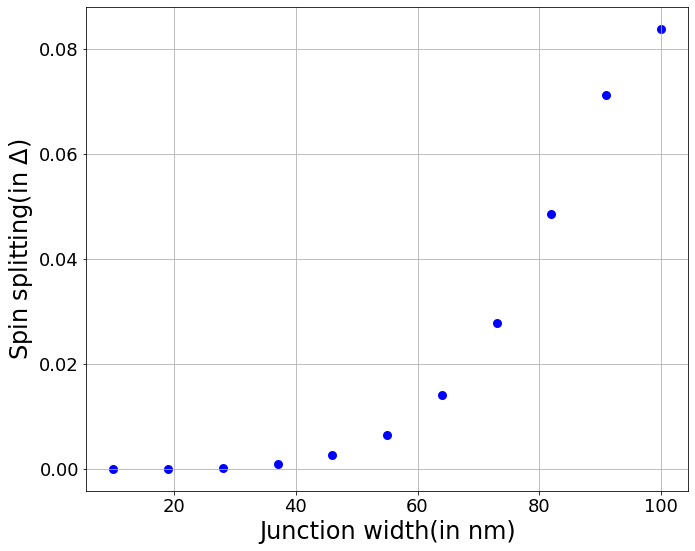

In [9]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Junction width(in nm)', fontsize=24)
plt.ylabel(r'Spin splitting(in $\Delta$)', fontsize=24)

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()

In [3]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 100, 11)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.5 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.5 + OMEGA        ## constant potential over reference level across all widths

K = 12

Ep_cu = np.empty((LY.shape[0],K) )
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10


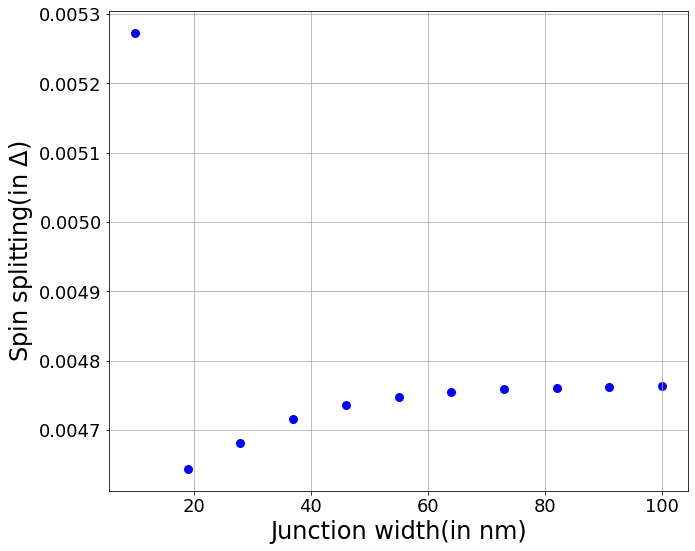

In [4]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

ax = plt.axis()

plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'Junction width(in nm)', fontsize=24)
plt.ylabel(r'Spin splitting(in $\Delta$)', fontsize=24)

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 

plt.grid(True)

plt.tight_layout()

plt.show()